# Secondary analyses

Scope: Secondary analyses in the WESAD protocol.

Input: Features and completed primary results.

Output and saved artifacts: `results/secondary_*.json` and predictions; `exploratory_status.json` (under the configured output root; real `.parquet`, synthetic `.csv`).

Dependencies: Environment from `requirements.txt`, `src/` modules; setup dependencies only in notebook 00.

Implemented exploratory extensions: four classes, XGBoost, LightGBM, MLP, late fusion, modality dropout, conformal prediction, and questionnaires. Separate outputs under `exploratory/`; requires `requirements-exploratory.txt` for boosting models.


In [1]:
from pathlib import Path
import os, sys
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / 'configs/config.yaml').is_file() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Start Jupyter inside the project folder; no machine-specific path is required')
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.config import load, setup, smoke_config
from src import workflow as w
SYNTHETIC = os.environ.get('WESAD_SYNTHETIC', '0') == '1'
c = load()
if SYNTHETIC: c = smoke_config(c)

# Reuse saved protocol instead of silently resetting extraction settings.
if not SYNTHETIC:
    import copy, json
    from src.config import fingerprint
    protocol_file = w.root(c) / 'protocol_lock.json'
    if protocol_file.is_file():
        from src.provenance import verify_lock
        saved_protocol = verify_lock(protocol_file)
        frozen = saved_protocol['config']
        if fingerprint(frozen) != saved_protocol['config_sha256']:
            raise ValueError('Saved protocol hash mismatch')
        c = copy.deepcopy(frozen)

setup(c)
print('Data mode:', 'SYNTHETIC EXECUTION ONLY' if SYNTHETIC else 'REAL WESAD')


Data mode: REAL WESAD


In [2]:
import copy
import json
from src.config import fingerprint, setup

output_root = w.root(c).resolve()
lock_file = output_root / "protocol_lock.json"

if not lock_file.is_file():
    raise FileNotFoundError(f"Protocollo non trovato: {lock_file}")

with lock_file.open("r", encoding="utf-8") as f:
    lock = json.load(f)
from src.provenance import verify_lock
verify_lock(lock_file)

c = copy.deepcopy(lock["config"])

if fingerprint(c) != lock["config_sha256"]:
    raise ValueError("Configurazione salvata e hash del protocollo non coincidono.")

if w.root(c).resolve() != output_root:
    raise ValueError("La cartella di output non coincide con quella del protocollo.")

setup(c)

feature_dir = w.root(c) / "features"
fmt = c["output"]["feature_format"]

for site in ("chest", "wrist"):
    path = feature_dir / f"{site}_features.{fmt}"
    if not path.is_file():
        raise FileNotFoundError(f"Feature mancanti: {path}")

if not list((w.root(c) / "results").glob("confirmatory_*_predictions.csv")):
    raise RuntimeError("Completa prima il notebook 04.")

tables = w.load_tables(c)
secondary = w.secondary_stage(tables, c)

for result in secondary:
    primary = result["primary"]
    low, high = primary["ci95"]
    print(
        f"{result['task']} | {result['site']} | {result['model']} | "
        f"Balanced accuracy: {primary['mean']:.3f} "
        f"[IC 95%: {low:.3f}, {high:.3f}]"
    )

if c.get("exploratory", {}).get("enabled", False):
    import warnings
    from src.exploratory import run

    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message=(
                r"X does not have valid feature names, "
                r"but LGBMClassifier was fitted with feature names"
            ),
            category=UserWarning,
        )
        exploratory_status = run(tables, c, synthetic=SYNTHETIC)

    print(exploratory_status)
else:
    print("Analisi esplorative disabilitate nella configurazione salvata.")


stress_vs_nonstress | early_fusion | logistic_regression | Balanced accuracy: 0.831 [IC 95%: 0.754, 0.900]
stress_vs_nonstress | chest | logistic_regression | Balanced accuracy: 0.822 [IC 95%: 0.740, 0.901]
stress_vs_nonstress | wrist | logistic_regression | Balanced accuracy: 0.903 [IC 95%: 0.851, 0.952]
baseline_vs_stress | early_fusion | logistic_regression | Balanced accuracy: 0.881 [IC 95%: 0.804, 0.947]
baseline_vs_stress | chest | logistic_regression | Balanced accuracy: 0.826 [IC 95%: 0.730, 0.919]
baseline_vs_stress | wrist | logistic_regression | Balanced accuracy: 0.912 [IC 95%: 0.854, 0.959]
availability_three_class | chest | logistic_regression | Balanced accuracy: 0.650 [IC 95%: 0.581, 0.721]
availability_three_class | wrist | logistic_regression | Balanced accuracy: 0.660 [IC 95%: 0.578, 0.742]
{'xgboost': {'status': 'completed', 'reason': None, 'analysis_role': 'exploratory'}, 'lightgbm': {'status': 'completed', 'reason': None, 'analysis_role': 'exploratory'}, 'mlp': {'

### Riepilogo: media e deviazione standard tra soggetti
Ogni soggetto ha lo stesso peso. La deviazione standard non è un intervallo di confidenza.

### availability_three_class · chest · logistic_regression

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC,log_loss,roc_auc_macro,average_precision_macro,pr_auc_macro
2,67,0.612,0.455,0.325,0.455,0.379,0.442,0.612,0.513,0.330,1.245,0.909,0.707,0.690
3,66,0.803,0.698,0.874,0.698,0.744,0.830,0.803,0.789,0.656,0.604,0.934,0.894,0.891
4,68,0.691,0.500,0.580,0.500,0.506,0.697,0.691,0.659,0.457,0.661,0.888,0.741,0.732
5,69,0.565,0.737,0.742,0.737,0.585,0.871,0.565,0.543,0.560,0.947,0.899,0.777,0.769
6,69,0.928,0.848,0.961,0.848,0.881,0.936,0.928,0.919,0.880,0.264,0.975,0.958,0.957
7,69,0.551,0.663,0.763,0.663,0.596,0.808,0.551,0.523,0.474,0.938,0.968,0.962,0.961
8,69,0.667,0.652,0.693,0.652,0.645,0.788,0.667,0.708,0.508,0.577,0.882,0.739,0.725
9,69,0.623,0.430,0.541,0.430,0.419,0.654,0.623,0.576,0.335,0.750,0.856,0.652,0.642
10,72,0.500,0.544,0.572,0.544,0.504,0.545,0.500,0.465,0.265,0.996,0.806,0.723,0.715
11,70,0.671,0.798,0.775,0.798,0.685,0.894,0.671,0.684,0.638,0.506,0.978,0.954,0.953


subject_id,class,support,precision,recall,f1,roc_auc,average_precision,pr_auc_trapezoidale
2,Baseline,37,0.725,1.000,0.841,0.987,0.992,0.992
2,Stress,19,0.000,0.000,0.000,0.925,0.765,0.752
2,Amusement,11,0.250,0.364,0.296,0.813,0.363,0.324
3,Baseline,37,0.766,0.973,0.857,0.884,0.894,0.892
3,Stress,18,0.857,0.667,0.750,0.932,0.848,0.844
3,Amusement,11,1.000,0.455,0.625,0.985,0.940,0.938
4,Baseline,37,0.740,1.000,0.851,0.967,0.971,0.970
4,Stress,20,1.000,0.500,0.667,1.000,1.000,1.000
4,Amusement,11,0.000,0.000,0.000,0.697,0.253,0.227
5,Baseline,38,1.000,0.211,0.348,0.920,0.926,0.925


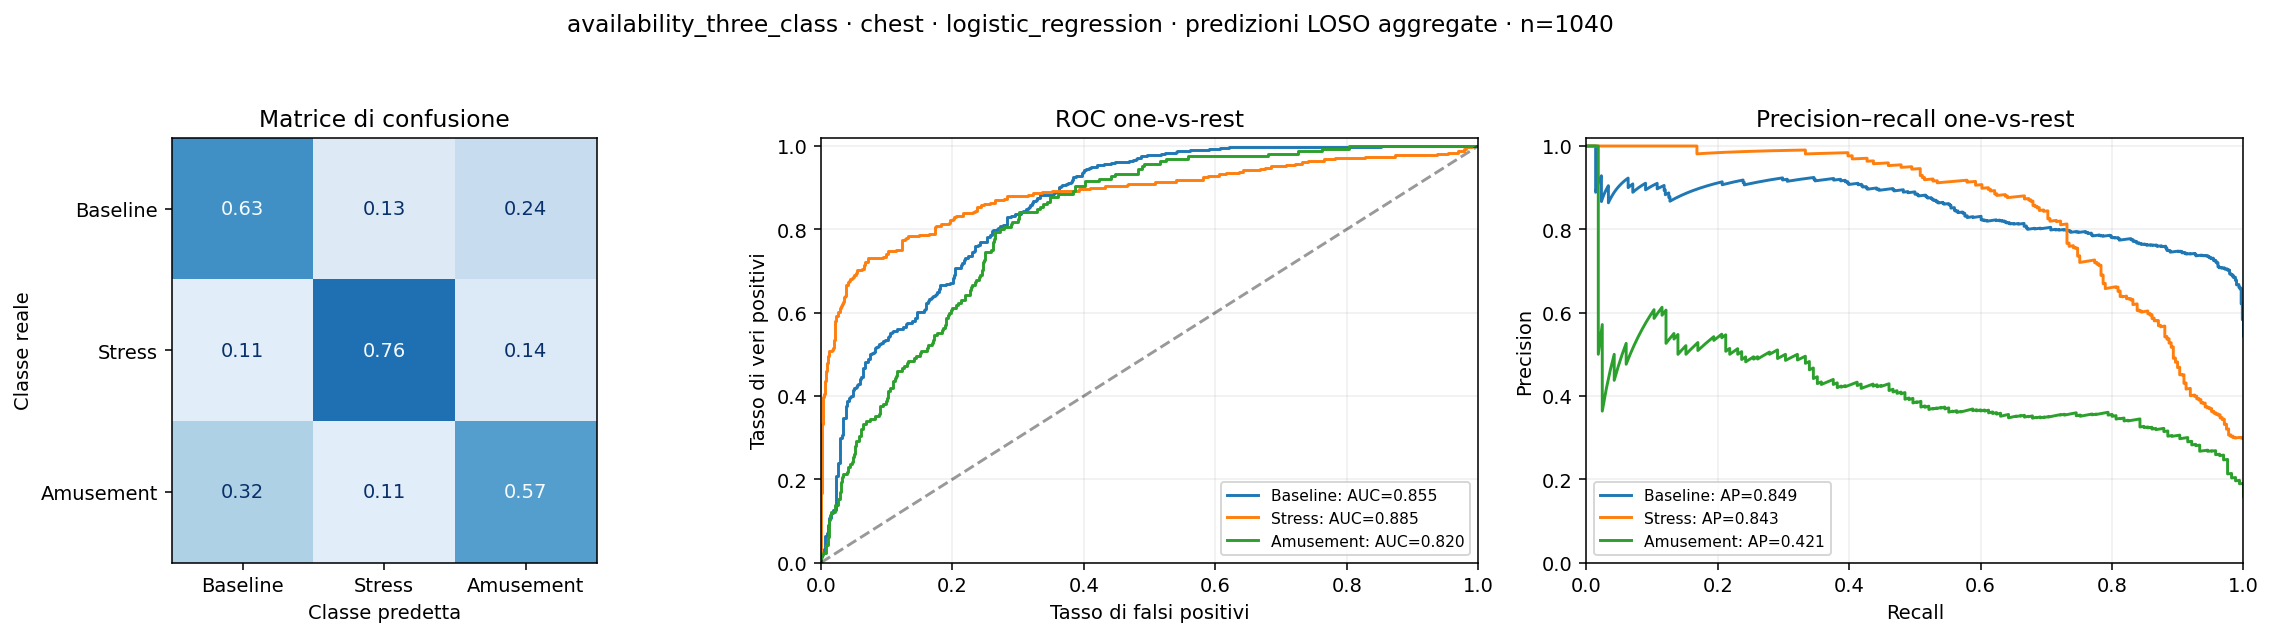

### availability_three_class · wrist · logistic_regression

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC,log_loss,roc_auc_macro,average_precision_macro,pr_auc_macro
2,65,0.769,0.599,0.904,0.599,0.609,0.836,0.769,0.718,0.606,0.517,0.954,0.887,0.883
3,68,0.662,0.613,0.620,0.613,0.610,0.711,0.662,0.682,0.461,0.631,0.848,0.701,0.685
4,68,0.456,0.432,0.500,0.432,0.458,0.566,0.456,0.497,0.210,0.662,0.702,0.599,0.593
5,62,0.855,0.838,0.822,0.838,0.828,0.856,0.855,0.853,0.766,0.503,0.909,0.852,0.846
6,66,0.742,0.822,0.790,0.822,0.741,0.905,0.742,0.776,0.672,0.490,0.961,0.914,0.912
7,69,0.797,0.877,0.787,0.877,0.798,0.861,0.797,0.793,0.724,0.547,0.972,0.976,0.975
8,69,0.797,0.755,0.783,0.755,0.747,0.840,0.797,0.801,0.671,0.585,0.901,0.815,0.799
9,69,0.696,0.737,0.781,0.737,0.670,0.895,0.696,0.732,0.608,0.861,0.935,0.845,0.829
10,71,0.577,0.495,0.514,0.495,0.501,0.621,0.577,0.595,0.341,0.680,0.786,0.623,0.614
11,66,0.864,0.813,0.824,0.813,0.818,0.860,0.864,0.861,0.760,0.349,0.936,0.871,0.867


subject_id,class,support,precision,recall,f1,roc_auc,average_precision,pr_auc_trapezoidale
2,Baseline,37,0.712,1.000,0.831,0.975,0.982,0.982
2,Stress,17,1.000,0.706,0.828,0.985,0.965,0.964
2,Amusement,11,1.000,0.091,0.167,0.902,0.714,0.704
3,Baseline,37,0.781,0.676,0.725,0.874,0.888,0.886
3,Stress,20,0.842,0.800,0.821,0.960,0.905,0.902
3,Amusement,11,0.235,0.364,0.286,0.711,0.312,0.267
4,Baseline,37,0.500,0.297,0.373,0.681,0.649,0.642
4,Stress,20,1.000,1.000,1.000,1.000,1.000,1.000
4,Amusement,11,0.000,0.000,0.000,0.424,0.148,0.136
5,Baseline,32,0.897,0.812,0.852,0.906,0.884,0.881


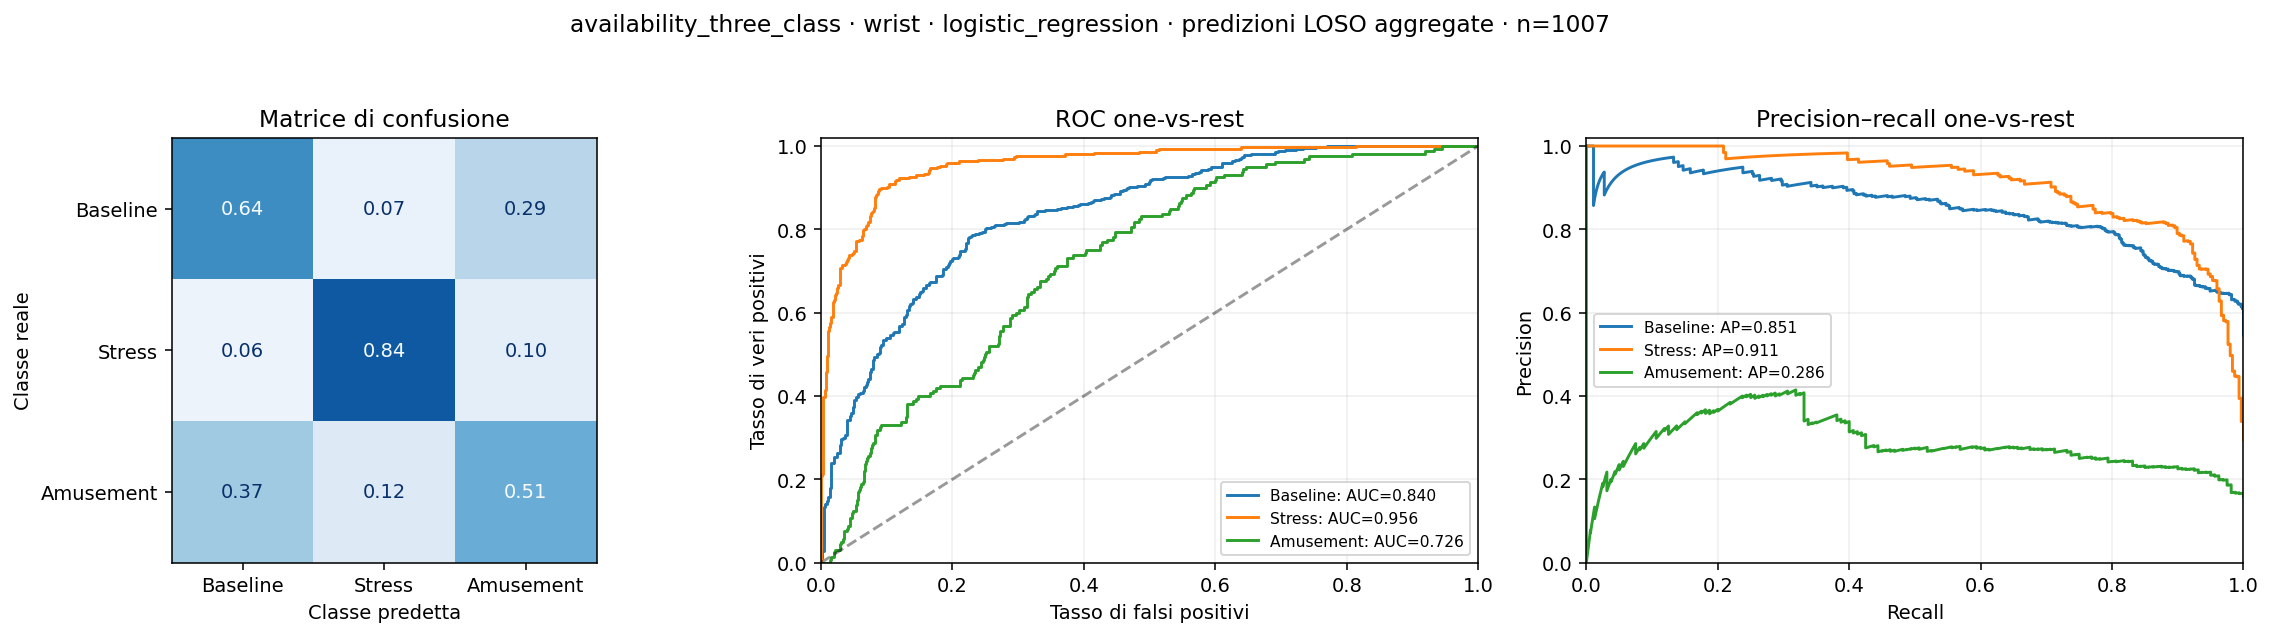

### baseline_vs_stress · chest · logistic_regression

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC,log_loss,roc_auc_macro,average_precision_macro,pr_auc_macro
2,54,0.685,0.500,0.343,0.500,0.407,0.469,0.685,0.557,0.000,0.771,0.981,0.975,0.974
3,55,0.891,0.848,0.903,0.848,0.868,0.895,0.891,0.887,0.749,0.418,0.950,0.935,0.932
4,57,0.860,0.800,0.911,0.800,0.826,0.885,0.860,0.849,0.702,0.313,0.997,0.997,0.997
5,52,0.981,0.984,0.976,0.984,0.980,0.982,0.981,0.981,0.961,0.084,1.000,1.000,1.000
6,56,0.964,0.974,0.950,0.974,0.960,0.968,0.964,0.965,0.923,0.069,1.000,1.000,1.000
7,58,0.569,0.671,0.722,0.671,0.563,0.808,0.569,0.546,0.390,0.708,1.000,1.000,1.000
8,58,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.079,1.000,1.000,1.000
9,58,0.793,0.712,0.835,0.712,0.730,0.815,0.793,0.771,0.533,0.365,0.970,0.960,0.959
10,60,0.450,0.496,0.496,0.496,0.446,0.523,0.450,0.435,-0.007,1.010,0.570,0.617,0.608
11,55,0.982,0.987,0.972,0.987,0.979,0.983,0.982,0.982,0.959,0.081,1.000,1.000,1.000


subject_id,class,support,precision,recall,f1,roc_auc,average_precision,pr_auc_trapezoidale
2,Baseline,37,0.685,1.000,0.813,0.981,0.992,0.992
2,Stress,17,0.000,0.000,0.000,0.981,0.957,0.955
3,Baseline,37,0.878,0.973,0.923,0.950,0.979,0.979
3,Stress,18,0.929,0.722,0.812,0.950,0.890,0.886
4,Baseline,37,0.822,1.000,0.902,0.997,0.999,0.999
4,Stress,20,1.000,0.600,0.750,0.997,0.995,0.995
5,Baseline,32,1.000,0.969,0.984,1.000,1.000,1.000
5,Stress,20,0.952,1.000,0.976,1.000,1.000,1.000
6,Baseline,38,1.000,0.947,0.973,1.000,1.000,1.000
6,Stress,18,0.900,1.000,0.947,1.000,1.000,1.000


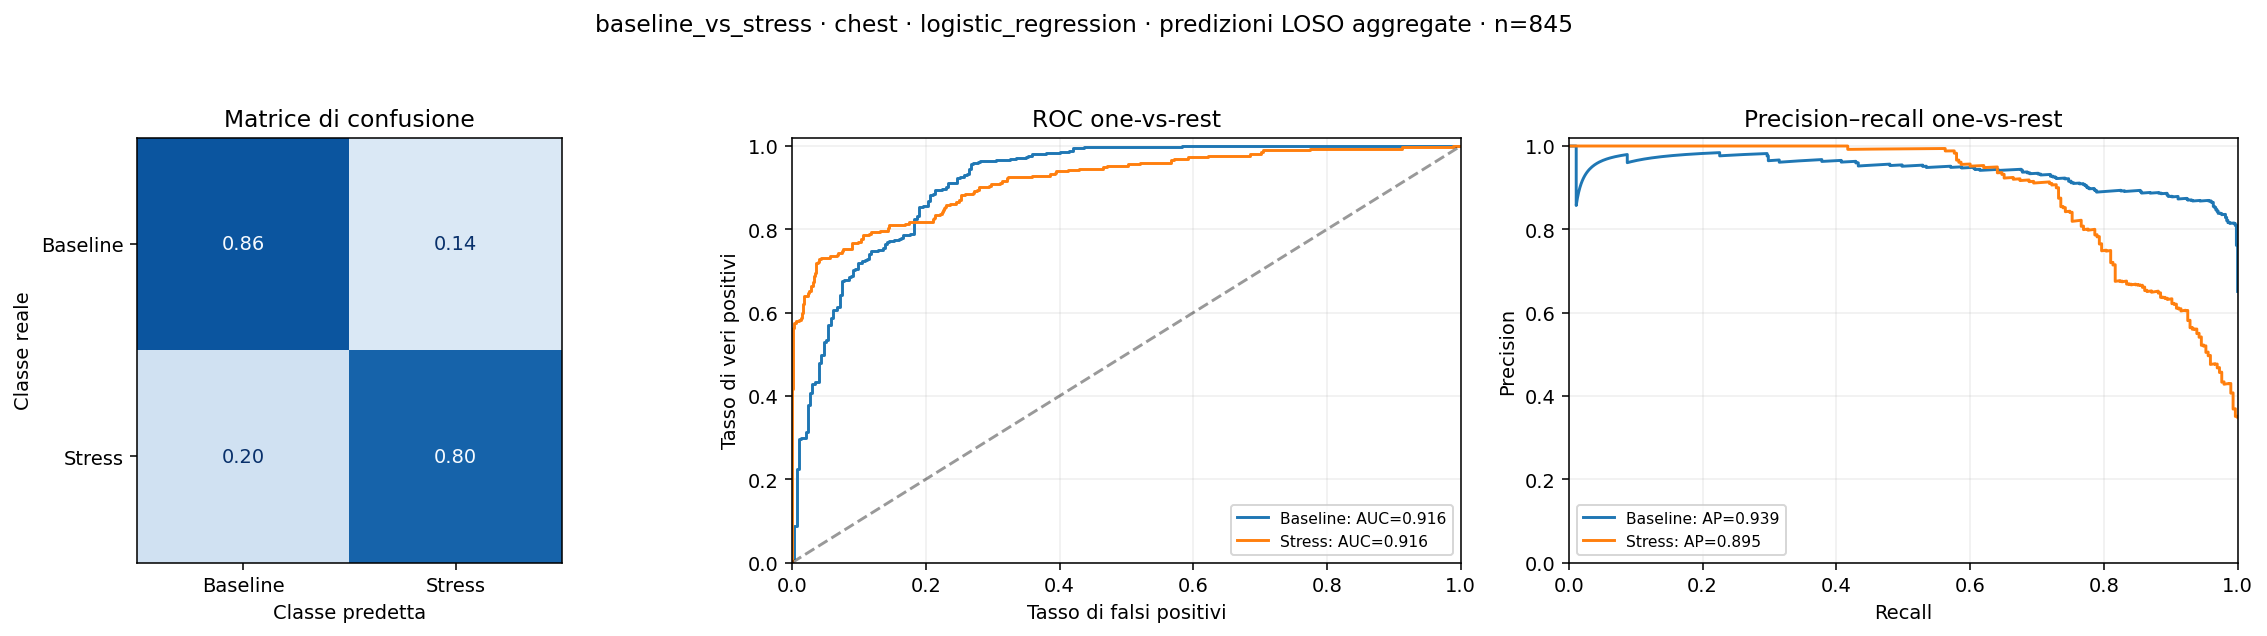

### baseline_vs_stress · early_fusion · logistic_regression

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC,log_loss,roc_auc_macro,average_precision_macro,pr_auc_macro
2,54,0.685,0.500,0.343,0.500,0.407,0.469,0.685,0.557,0.000,1.163,0.998,0.998,0.998
3,55,0.873,0.820,0.890,0.820,0.843,0.879,0.873,0.866,0.706,0.382,0.964,0.953,0.951
4,57,0.895,0.850,0.930,0.850,0.874,0.909,0.895,0.889,0.776,0.154,1.000,1.000,1.000
5,52,0.962,0.969,0.955,0.969,0.960,0.965,0.962,0.962,0.923,0.069,1.000,1.000,1.000
6,56,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.046,1.000,1.000,1.000
7,58,0.690,0.763,0.763,0.763,0.690,0.837,0.690,0.690,0.526,1.257,1.000,1.000,1.000
8,58,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.042,1.000,1.000,1.000
9,58,0.879,0.825,0.922,0.825,0.852,0.898,0.879,0.872,0.741,0.353,1.000,1.000,1.000
10,60,0.933,0.946,0.926,0.946,0.931,0.943,0.933,0.934,0.872,0.244,1.000,1.000,1.000
11,55,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.026,1.000,1.000,1.000


subject_id,class,support,precision,recall,f1,roc_auc,average_precision,pr_auc_trapezoidale
2,Baseline,37,0.685,1.000,0.813,0.998,0.999,0.999
2,Stress,17,0.000,0.000,0.000,0.998,0.997,0.997
3,Baseline,37,0.857,0.973,0.911,0.964,0.985,0.985
3,Stress,18,0.923,0.667,0.774,0.964,0.921,0.918
4,Baseline,37,0.860,1.000,0.925,1.000,1.000,1.000
4,Stress,20,1.000,0.700,0.824,1.000,1.000,1.000
5,Baseline,32,1.000,0.938,0.968,1.000,1.000,1.000
5,Stress,20,0.909,1.000,0.952,1.000,1.000,1.000
6,Baseline,38,1.000,1.000,1.000,1.000,1.000,1.000
6,Stress,18,1.000,1.000,1.000,1.000,1.000,1.000


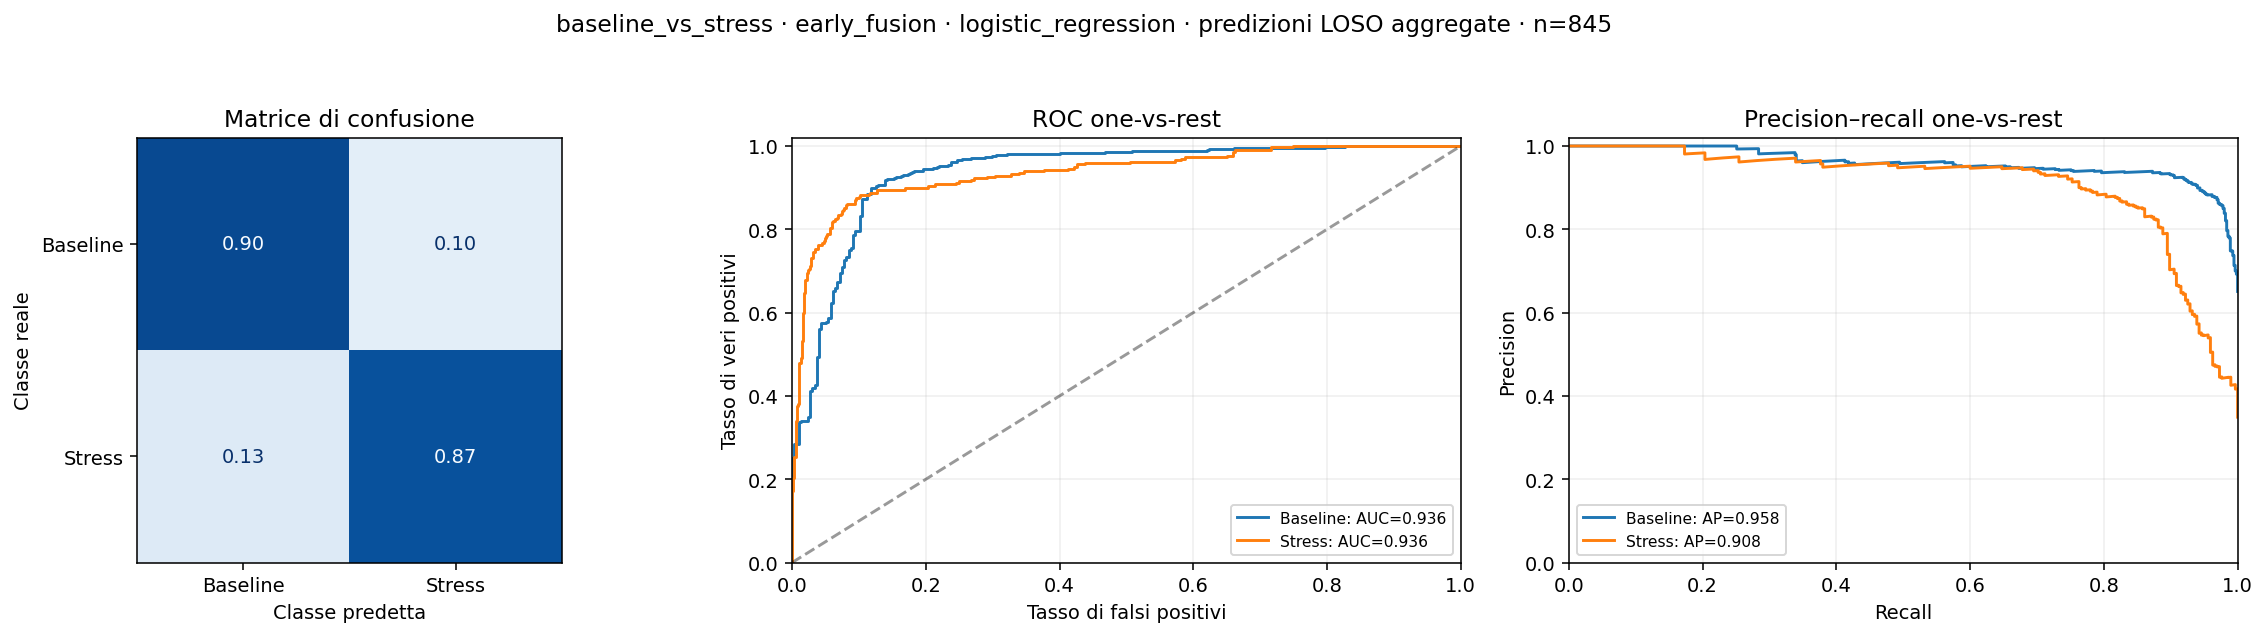

### baseline_vs_stress · wrist · logistic_regression

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC,log_loss,roc_auc_macro,average_precision_macro,pr_auc_macro
2,54,0.926,0.882,0.951,0.882,0.908,0.933,0.926,0.923,0.831,0.207,0.995,0.994,0.994
3,55,0.927,0.932,0.911,0.932,0.920,0.932,0.927,0.928,0.842,0.172,0.985,0.982,0.982
4,57,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.117,1.000,1.000,1.000
5,52,0.942,0.953,0.935,0.953,0.941,0.950,0.942,0.943,0.888,0.153,0.997,0.997,0.997
6,56,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.123,1.000,1.000,1.000
7,58,0.862,0.895,0.857,0.895,0.858,0.901,0.862,0.865,0.751,0.290,1.000,1.000,1.000
8,58,0.966,0.952,0.974,0.952,0.962,0.967,0.966,0.965,0.926,0.189,0.990,0.990,0.990
9,58,0.845,0.775,0.904,0.775,0.802,0.875,0.845,0.831,0.667,0.382,0.946,0.950,0.950
10,60,0.967,0.973,0.960,0.973,0.965,0.969,0.967,0.967,0.933,0.185,1.000,1.000,1.000
11,55,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.051,1.000,1.000,1.000


subject_id,class,support,precision,recall,f1,roc_auc,average_precision,pr_auc_trapezoidale
2,Baseline,37,0.902,1.000,0.949,0.995,0.998,0.998
2,Stress,17,1.000,0.765,0.867,0.995,0.990,0.990
3,Baseline,37,0.971,0.919,0.944,0.985,0.993,0.993
3,Stress,18,0.850,0.944,0.895,0.985,0.971,0.971
4,Baseline,37,1.000,1.000,1.000,1.000,1.000,1.000
4,Stress,20,1.000,1.000,1.000,1.000,1.000,1.000
5,Baseline,32,1.000,0.906,0.951,0.997,0.998,0.998
5,Stress,20,0.870,1.000,0.930,0.997,0.995,0.995
6,Baseline,38,1.000,1.000,1.000,1.000,1.000,1.000
6,Stress,18,1.000,1.000,1.000,1.000,1.000,1.000


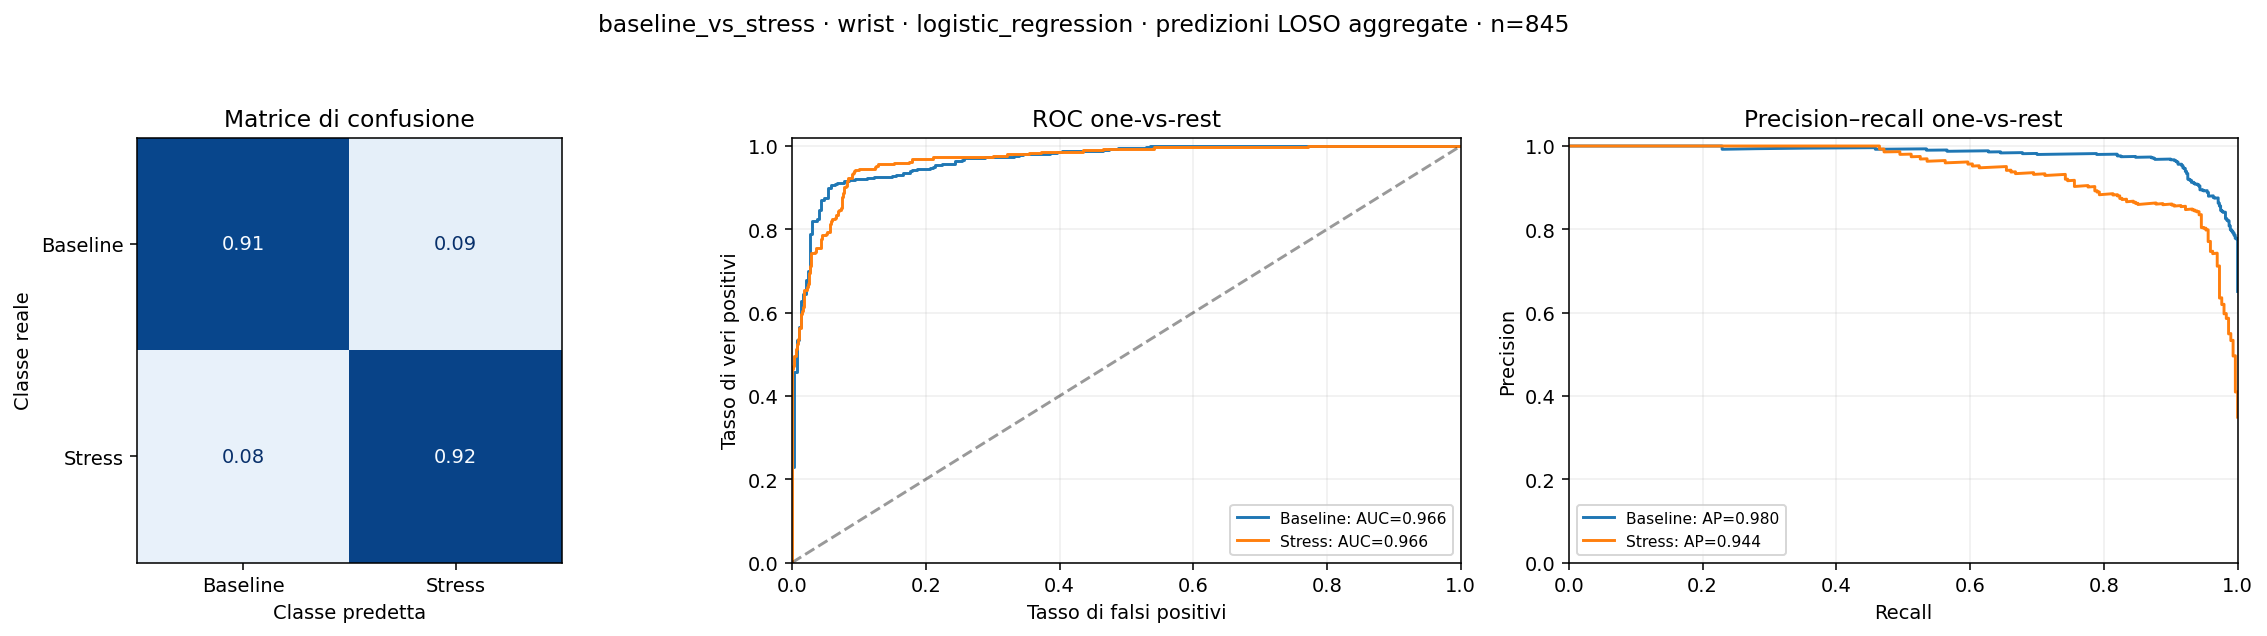

### stress_vs_nonstress · chest · logistic_regression

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC,log_loss,roc_auc_macro,average_precision_macro,pr_auc_macro
2,65,0.738,0.500,0.369,0.500,0.425,0.545,0.738,0.627,0.000,1.489,0.950,0.908,0.903
3,66,0.909,0.868,0.897,0.868,0.881,0.908,0.909,0.907,0.765,0.247,0.965,0.943,0.940
4,68,0.838,0.725,0.907,0.725,0.759,0.868,0.838,0.816,0.605,0.316,0.993,0.990,0.990
5,62,0.935,0.952,0.917,0.952,0.930,0.946,0.935,0.937,0.868,0.112,1.000,1.000,1.000
6,66,0.970,0.979,0.950,0.979,0.963,0.973,0.970,0.970,0.929,0.157,1.000,1.000,1.000
7,69,0.768,0.837,0.778,0.837,0.760,0.871,0.768,0.779,0.612,0.801,1.000,1.000,1.000
8,69,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.099,1.000,1.000,1.000
9,69,0.754,0.575,0.871,0.575,0.557,0.817,0.754,0.681,0.334,0.459,0.860,0.837,0.834
10,71,0.634,0.718,0.713,0.718,0.634,0.800,0.634,0.636,0.431,0.591,0.875,0.873,0.871
11,66,0.970,0.980,0.947,0.980,0.962,0.973,0.970,0.970,0.926,0.086,1.000,1.000,1.000


subject_id,class,support,precision,recall,f1,roc_auc,average_precision,pr_auc_trapezoidale
2,Non-stress,48,0.738,1.000,0.850,0.950,0.984,0.984
2,Stress,17,0.000,0.000,0.000,0.950,0.831,0.821
3,Non-stress,48,0.920,0.958,0.939,0.965,0.988,0.988
3,Stress,18,0.875,0.778,0.824,0.965,0.897,0.893
4,Non-stress,48,0.814,1.000,0.897,0.993,0.997,0.997
4,Stress,20,1.000,0.450,0.621,0.993,0.983,0.983
5,Non-stress,42,1.000,0.905,0.950,1.000,1.000,1.000
5,Stress,20,0.833,1.000,0.909,1.000,1.000,1.000
6,Non-stress,48,1.000,0.958,0.979,1.000,1.000,1.000
6,Stress,18,0.900,1.000,0.947,1.000,1.000,1.000


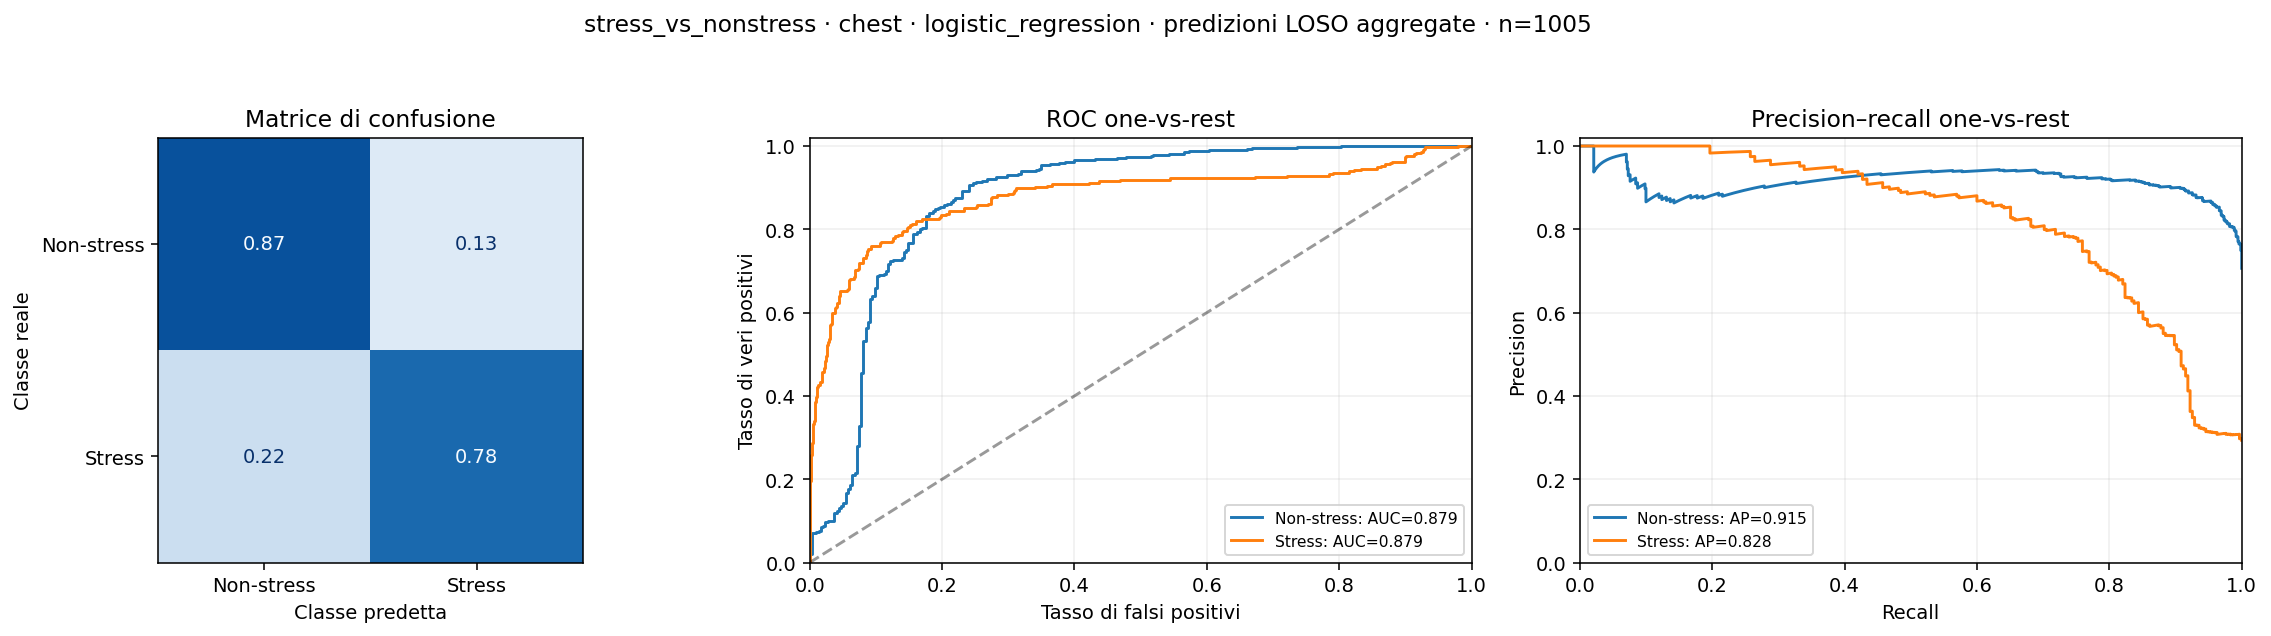

### stress_vs_nonstress · early_fusion · logistic_regression

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC,log_loss,roc_auc_macro,average_precision_macro,pr_auc_macro
2,65,0.738,0.500,0.369,0.500,0.425,0.545,0.738,0.627,0.000,0.787,0.977,0.956,0.955
3,66,0.909,0.851,0.916,0.851,0.876,0.911,0.909,0.905,0.764,0.233,0.976,0.960,0.959
4,68,0.838,0.725,0.907,0.725,0.759,0.868,0.838,0.816,0.605,0.276,1.000,1.000,1.000
5,62,0.952,0.964,0.935,0.964,0.947,0.958,0.952,0.952,0.899,0.102,1.000,1.000,1.000
6,66,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.057,1.000,1.000,1.000
7,69,0.797,0.857,0.794,0.857,0.787,0.881,0.797,0.806,0.648,0.523,1.000,1.000,1.000
8,69,0.986,0.976,0.990,0.976,0.983,0.986,0.986,0.985,0.966,0.066,1.000,1.000,1.000
9,69,0.826,0.700,0.902,0.700,0.731,0.860,0.826,0.798,0.567,0.394,0.970,0.970,0.970
10,71,0.958,0.969,0.942,0.969,0.953,0.963,0.958,0.958,0.911,0.176,1.000,1.000,1.000
11,66,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.025,1.000,1.000,1.000


subject_id,class,support,precision,recall,f1,roc_auc,average_precision,pr_auc_trapezoidale
2,Non-stress,48,0.738,1.000,0.850,0.977,0.993,0.993
2,Stress,17,0.000,0.000,0.000,0.977,0.920,0.917
3,Non-stress,48,0.904,0.979,0.940,0.976,0.992,0.992
3,Stress,18,0.929,0.722,0.812,0.976,0.928,0.926
4,Non-stress,48,0.814,1.000,0.897,1.000,1.000,1.000
4,Stress,20,1.000,0.450,0.621,1.000,1.000,1.000
5,Non-stress,42,1.000,0.929,0.963,1.000,1.000,1.000
5,Stress,20,0.870,1.000,0.930,1.000,1.000,1.000
6,Non-stress,48,1.000,1.000,1.000,1.000,1.000,1.000
6,Stress,18,1.000,1.000,1.000,1.000,1.000,1.000


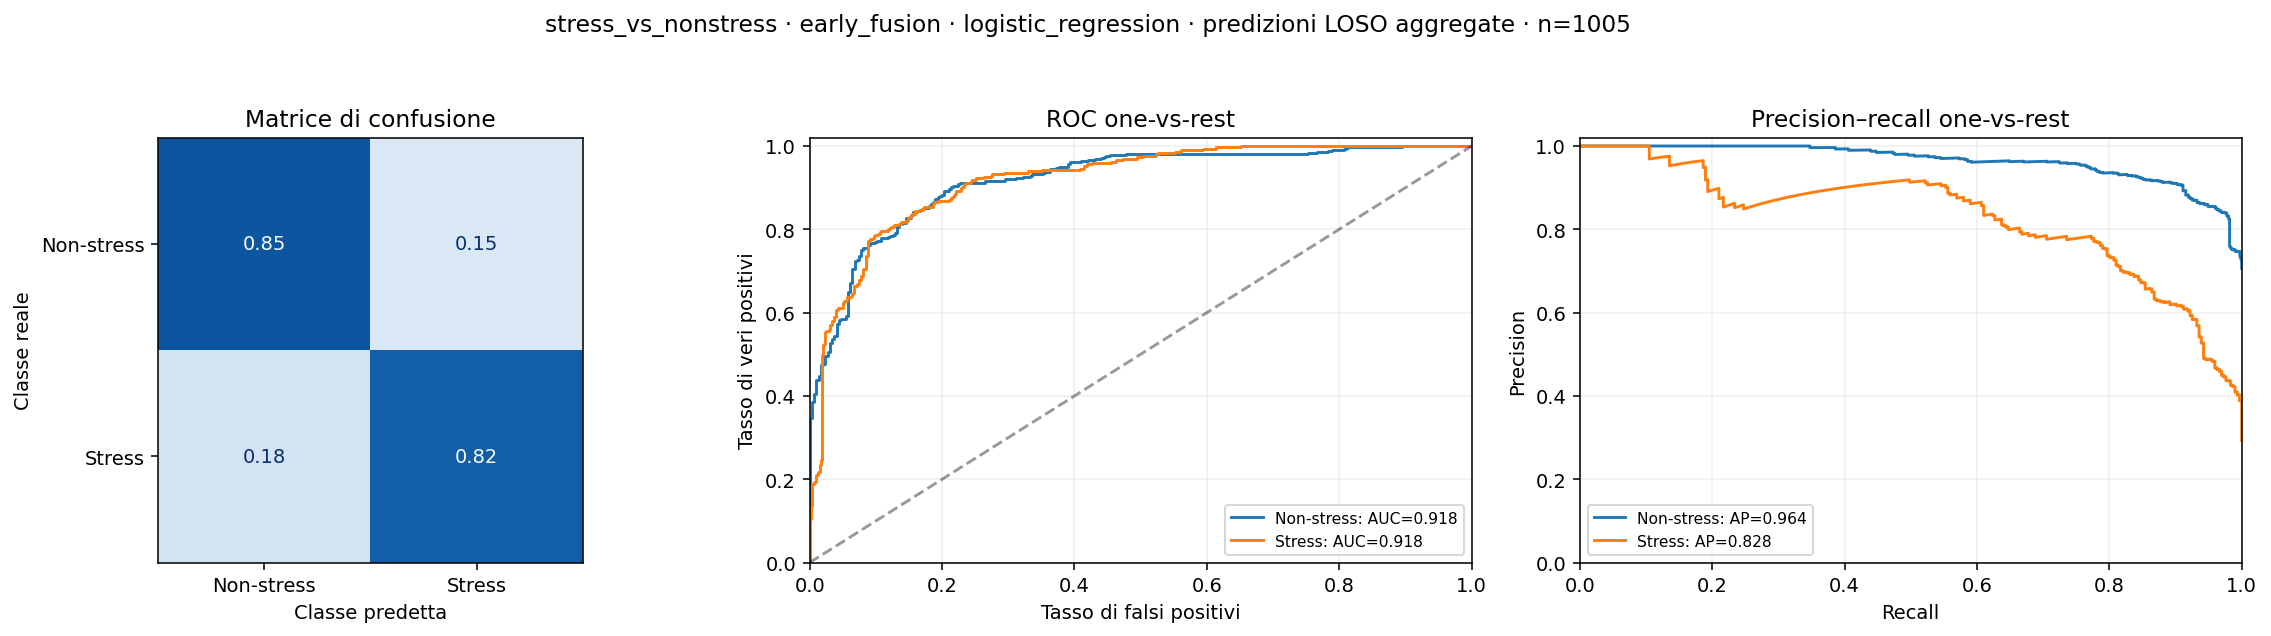

### stress_vs_nonstress · wrist · logistic_regression

subject_id,n_windows,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,MCC,log_loss,roc_auc_macro,average_precision_macro,pr_auc_macro
2,65,0.923,0.872,0.925,0.872,0.894,0.923,0.923,0.921,0.795,0.208,0.984,0.979,0.978
3,66,0.924,0.913,0.900,0.913,0.906,0.926,0.924,0.925,0.813,0.193,0.978,0.967,0.966
4,68,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.072,1.000,1.000,1.000
5,62,0.952,0.964,0.935,0.964,0.947,0.958,0.952,0.952,0.899,0.142,0.994,0.993,0.993
6,66,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.103,1.000,1.000,1.000
7,69,0.884,0.918,0.857,0.918,0.872,0.917,0.884,0.889,0.773,0.268,1.000,1.000,1.000
8,69,0.971,0.952,0.980,0.952,0.965,0.972,0.971,0.971,0.932,0.150,0.992,0.992,0.991
9,69,0.870,0.775,0.922,0.775,0.813,0.890,0.870,0.856,0.682,0.363,0.936,0.939,0.938
10,71,0.972,0.979,0.960,0.979,0.969,0.974,0.972,0.972,0.939,0.158,1.000,1.000,1.000
11,66,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.059,1.000,1.000,1.000


subject_id,class,support,precision,recall,f1,roc_auc,average_precision,pr_auc_trapezoidale
2,Non-stress,48,0.922,0.979,0.949,0.984,0.994,0.994
2,Stress,17,0.929,0.765,0.839,0.984,0.963,0.962
3,Non-stress,48,0.957,0.938,0.947,0.978,0.993,0.992
3,Stress,18,0.842,0.889,0.865,0.978,0.941,0.939
4,Non-stress,48,1.000,1.000,1.000,1.000,1.000,1.000
4,Stress,20,1.000,1.000,1.000,1.000,1.000,1.000
5,Non-stress,42,1.000,0.929,0.963,0.994,0.997,0.997
5,Stress,20,0.870,1.000,0.930,0.994,0.988,0.988
6,Non-stress,48,1.000,1.000,1.000,1.000,1.000,1.000
6,Stress,18,1.000,1.000,1.000,1.000,1.000,1.000


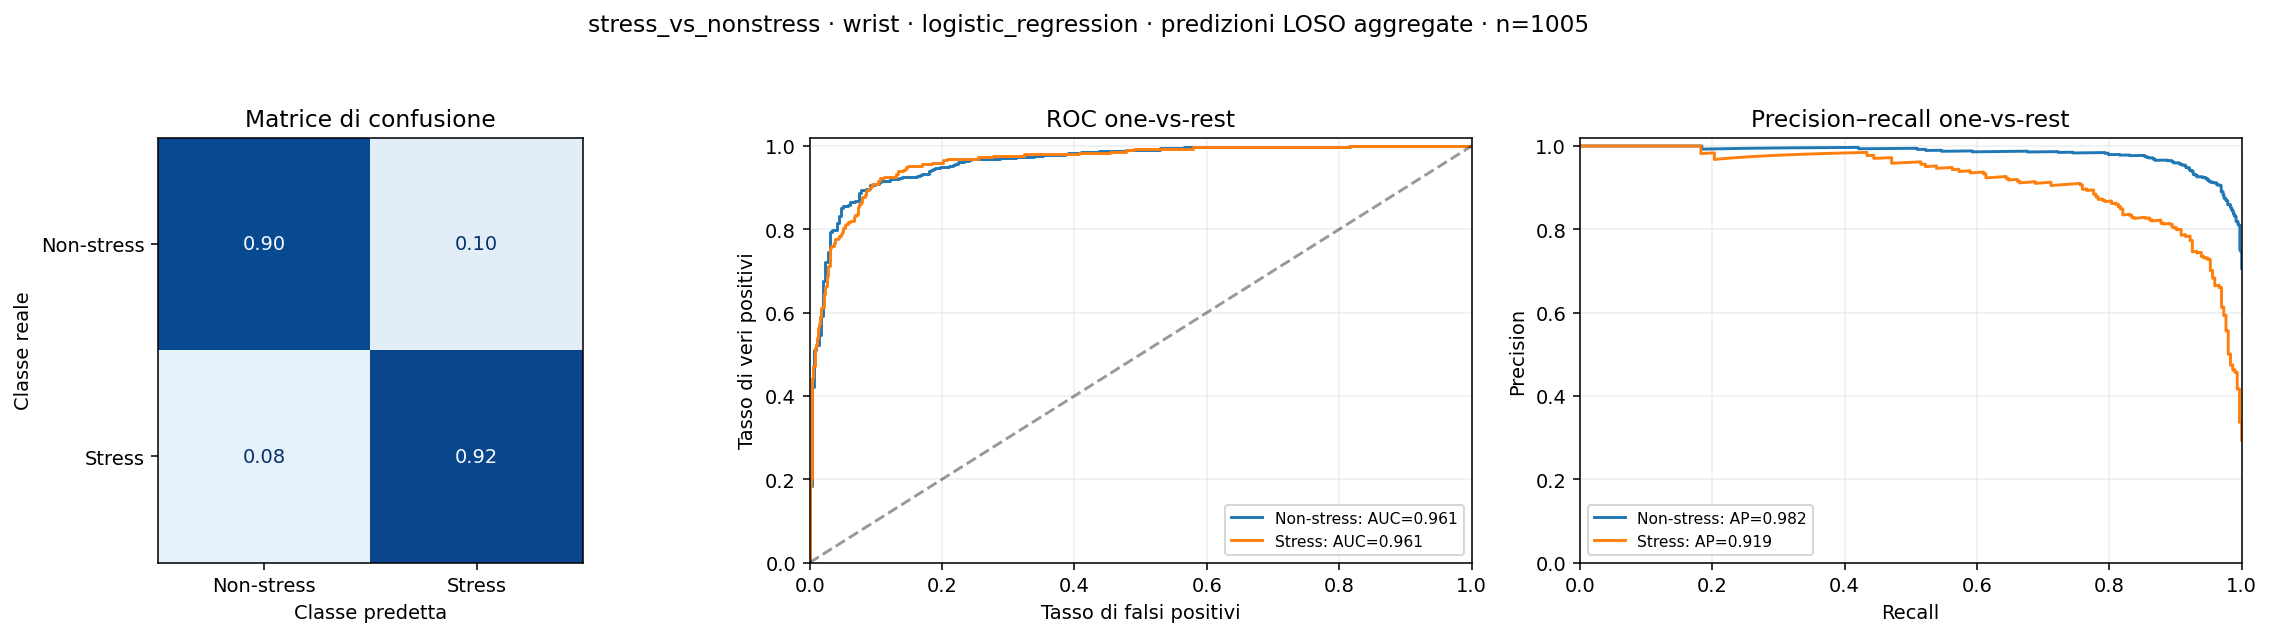

**Lettura:** i grafici aggregati combinano le finestre di test LOSO; le loro AUC possono differire dalle medie per soggetto. AP è average precision e differisce dall'area PR trapezoidale. N/D indica una metrica non definita; precision/recall/F1 con denominatore nullo valgono 0. Le analisi availability usano finestre disponibili per ciascuna modalità e non costituiscono un confronto sugli stessi campioni.

In [3]:
import json
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Image, Markdown
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    matthews_corrcoef,
    log_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)

GRAFICI_PER_SOGGETTO = False
SOGGETTI = None             # None = tutti; esempio: [2, 5, 15]
NORMALIZZA = True           # Matrici normalizzate per classe reale

results_dir = w.root(c) / "results"
files = sorted(results_dir.glob("secondary_*_predictions.csv"))

if not files:
    raise FileNotFoundError("Nessuna predizione secondaria trovata.")

metric_rows = []
class_rows = []
experiments = []

def class_labels(task, classes):
    mapping = (
        {0: "Non-stress", 1: "Stress"}
        if task == "stress_vs_nonstress"
        else {1: "Baseline", 2: "Stress", 3: "Amusement"}
    )
    return [mapping.get(int(k), str(k)) for k in classes]

def show_png(fig):
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
        png = buffer.getvalue()
    plt.close(fig)
    display(Image(data=png))

def plot_results(frame, metadata, title):
    classes = np.asarray(metadata["classes"], dtype=int)
    names = class_labels(metadata["task"], classes)
    y = frame["label"].to_numpy(dtype=int)
    p = frame[[f"p_{k}" for k in classes]].to_numpy(dtype=float)
    predicted = classes[p.argmax(axis=1)]

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

    matrix = confusion_matrix(
        y, predicted, labels=classes,
        normalize="true" if NORMALIZZA else None,
    )
    ConfusionMatrixDisplay(matrix, display_labels=names).plot(
        ax=axes[0],
        cmap="Blues",
        colorbar=False,
        values_format=".2f" if NORMALIZZA else "d",
        im_kw={"vmin": 0, "vmax": 1} if NORMALIZZA else None,
    )
    axes[0].set(
        title="Matrice di confusione",
        xlabel="Classe predetta",
        ylabel="Classe reale",
    )

    for j, name in enumerate(names):
        binary = (y == classes[j]).astype(int)
        if np.unique(binary).size < 2:
            continue

        fpr, tpr, _ = roc_curve(binary, p[:, j])
        axes[1].plot(
            fpr, tpr, label=f"{name}: AUC={auc(fpr, tpr):.3f}"
        )

        precision, recall, _ = precision_recall_curve(binary, p[:, j])
        ap = average_precision_score(binary, p[:, j])
        axes[2].plot(recall, precision, label=f"{name}: AP={ap:.3f}")

    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axes[1].set(
        title="ROC one-vs-rest",
        xlabel="Tasso di falsi positivi",
        ylabel="Tasso di veri positivi",
        xlim=(0, 1), ylim=(0, 1.02),
    )
    axes[2].set(
        title="Precision–recall one-vs-rest",
        xlabel="Recall", ylabel="Precision",
        xlim=(0, 1), ylim=(0, 1.02),
    )

    for ax in axes[1:]:
        ax.legend(fontsize=8, loc="best")
        ax.grid(alpha=0.2)

    fig.suptitle(title, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    show_png(fig)

for file in files:
    tag = file.name.removesuffix("_predictions.csv")
    with (results_dir / f"{tag}.json").open("r", encoding="utf-8") as f:
        metadata = json.load(f)

    frame = pd.read_csv(file)
    classes = np.asarray(metadata["classes"], dtype=int)
    names = class_labels(metadata["task"], classes)
    columns = [f"p_{k}" for k in classes]

    probabilities = frame[columns].to_numpy(dtype=float)
    if (
        not np.isfinite(probabilities).all()
        or (probabilities < 0).any()
        or (probabilities > 1).any()
        or not np.allclose(probabilities.sum(axis=1), 1)
    ):
        raise ValueError(f"Probabilità non valide: {file.name}")

    if not frame["label"].isin(classes).all():
        raise ValueError(f"Label inattese: {file.name}")

    if SOGGETTI is not None:
        frame = frame[frame["subject_id"].isin(SOGGETTI)].copy()

    if frame.empty:
        continue

    experiments.append((metadata, frame))

    for subject_id, subject in frame.groupby("subject_id"):
        y = subject["label"].to_numpy(dtype=int)
        p = subject[columns].to_numpy(dtype=float)
        predicted = classes[p.argmax(axis=1)]

        precision, recall, f1, support = precision_recall_fscore_support(
            y, predicted, labels=classes, zero_division=0
        )
        weighted = precision_recall_fscore_support(
            y, predicted, labels=classes,
            average="weighted", zero_division=0,
        )

        common = {
            "task": metadata["task"],
            "site": metadata["site"],
            "model": metadata["model"],
            "subject_id": int(subject_id),
        }

        roc_values, ap_values, pr_values = [], [], []

        for j, name in enumerate(names):
            binary = (y == classes[j]).astype(int)
            roc_auc = ap = pr_auc = np.nan

            if np.unique(binary).size == 2:
                fpr, tpr, _ = roc_curve(binary, p[:, j])
                roc_auc = auc(fpr, tpr)
                pr_precision, pr_recall, _ = precision_recall_curve(
                    binary, p[:, j]
                )
                pr_auc = auc(pr_recall, pr_precision)
                ap = average_precision_score(binary, p[:, j])

            roc_values.append(roc_auc)
            ap_values.append(ap)
            pr_values.append(pr_auc)

            class_rows.append({
                **common,
                "class": name,
                "support": int(support[j]),
                "precision": precision[j],
                "recall": recall[j],
                "f1": f1[j],
                "roc_auc": roc_auc,
                "average_precision": ap,
                "pr_auc_trapezoidale": pr_auc,
            })

        metric_rows.append({
            **common,
            "n_windows": len(subject),
            "accuracy": accuracy_score(y, predicted),
            "balanced_accuracy": balanced_accuracy_score(y, predicted),
            "precision_macro": precision.mean(),
            "recall_macro": recall.mean(),
            "f1_macro": f1.mean(),
            "precision_weighted": weighted[0],
            "recall_weighted": weighted[1],
            "f1_weighted": weighted[2],
            "MCC": matthews_corrcoef(y, predicted),
            "log_loss": log_loss(y, p, labels=classes),
            "roc_auc_macro": np.mean(roc_values),
            "average_precision_macro": np.mean(ap_values),
            "pr_auc_macro": np.mean(pr_values),
        })

subject_metrics = pd.DataFrame(metric_rows)
class_metrics = pd.DataFrame(class_rows)

if subject_metrics.empty:
    raise ValueError("Nessun soggetto corrisponde alla selezione.")

keys = ["task", "site", "model"]
metric_columns = [
    col for col in subject_metrics.columns
    if col not in keys + ["subject_id", "n_windows"]
]

display(Markdown(
    "### Riepilogo: media e deviazione standard tra soggetti\n"
    "Ogni soggetto ha lo stesso peso. La deviazione standard "
    "non è un intervallo di confidenza."
))
summary_metrics = subject_metrics.groupby(keys)[metric_columns].agg(
    ["mean", "std"]
)
display(summary_metrics.style.format("{:.3f}", na_rep="N/D"))

for metadata, frame in experiments:
    mask = (
        (subject_metrics["task"] == metadata["task"])
        & (subject_metrics["site"] == metadata["site"])
        & (subject_metrics["model"] == metadata["model"])
    )
    detail_mask = (
        (class_metrics["task"] == metadata["task"])
        & (class_metrics["site"] == metadata["site"])
        & (class_metrics["model"] == metadata["model"])
    )

    title = (
        f"{metadata['task']} · {metadata['site']} · {metadata['model']}"
    )
    display(Markdown(f"### {title}"))

    display(
        subject_metrics.loc[mask].drop(columns=keys)
        .style.format({col: "{:.3f}" for col in metric_columns}, na_rep="N/D")
        .hide(axis="index")
    )
    display(
        class_metrics.loc[detail_mask].drop(columns=keys)
        .style.format({
            col: "{:.3f}" for col in [
                "precision", "recall", "f1", "roc_auc",
                "average_precision", "pr_auc_trapezoidale",
            ]
        }, na_rep="N/D")
        .hide(axis="index")
    )

    plot_results(
        frame, metadata,
        f"{title} · predizioni LOSO aggregate · n={len(frame)}",
    )

    if GRAFICI_PER_SOGGETTO:
        for subject_id, subject in frame.groupby("subject_id"):
            plot_results(
                subject, metadata,
                f"{title} · S{int(subject_id)} · n={len(subject)}",
            )

display(Markdown(
    "**Lettura:** i grafici aggregati combinano le finestre di test LOSO; "
    "le loro AUC possono differire dalle medie per soggetto. "
    "AP è average precision e differisce dall'area PR trapezoidale. "
    "N/D indica una metrica non definita; precision/recall/F1 con "
    "denominatore nullo valgono 0. "
    "Le analisi availability usano finestre disponibili per ciascuna "
    "modalità e non costituiscono un confronto sugli stessi campioni."
))

## Interpretation of secondary and exploratory analyses

### Scope and evaluation

This notebook extends the primary baseline/stress/amusement analysis through:

- Secondary binary classification tasks.
- Modality-specific window-availability analyses.
- Exploratory classifiers and fusion strategies.
- Four-class classification including meditation.
- Exploratory conformal prediction and selective prediction.
- Descriptive self-report analyses.

Classification results use LOSO evaluation across **15 participants**.
Unless explicitly stated otherwise, reported metrics are averaged equally
across participants.

Confidence intervals are conditional subject-bootstrap intervals based on
the fitted LOSO predictions. They do not include retraining during
bootstrap resampling.

### 1. Stress versus non-stress

Baseline and amusement are combined into the non-stress class. Logistic
regression is evaluated on **1,005 common valid windows**.

| Configuration | Balanced accuracy | Conditional 95% CI | Macro F1 | Macro ROC AUC |
|---|---:|---|---:|---:|
| Chest | 82.16% | [73.95%, 90.08%] | 0.792 | 0.940 |
| Wrist | **90.33%** | [85.05%, 95.16%] | **0.889** | 0.975 |
| Early fusion | 83.10% | [75.36%, 90.05%] | 0.804 | **0.978** |

Wrist logistic regression achieves the highest observed balanced accuracy.
Early fusion has a slightly higher ROC AUC, but this does not translate
into better final classification decisions.

For the wrist model, the aggregated confusion matrix shows:

- **270/295 stress windows correctly recognized:** recall 91.5%.
- **25 stress windows classified as non-stress.**
- **636/710 non-stress windows correctly recognized:** recall 89.6%.
- **74 non-stress windows classified as stress.**
- Stress precision: **78.5%**.

These pooled-window metrics differ from equal-participant averages.

The results support discrimination of the laboratory stress condition from
the other evaluated conditions. They do not establish detection of
everyday stress or continuous psychological stress intensity.

### 2. Baseline versus stress

Amusement is excluded from both training and testing. Logistic regression
is evaluated on **845 common valid windows**.

| Configuration | Balanced accuracy | Conditional 95% CI | Macro F1 | Macro ROC AUC |
|---|---:|---|---:|---:|
| Chest | 82.61% | [72.98%, 91.91%] | 0.808 | 0.944 |
| Wrist | **91.22%** | [85.45%, 95.89%] | **0.904** | 0.977 |
| Early fusion | 88.10% | [80.38%, 94.70%] | 0.866 | **0.990** |

The wrist model again has the highest observed balanced accuracy.

Its aggregated confusion matrix contains:

- **501/550 baseline windows correctly classified:** recall 91.1%.
- **272/295 stress windows correctly classified:** recall 92.2%.
- **49 baseline windows classified as stress.**
- **23 stress windows classified as baseline.**
- Stress precision: **84.7%**.

This is a different learning task from stress/non-stress, not simply the
same fitted model evaluated after removing amusement.

The high AUC of early fusion indicates strong ranking performance.
It does not imply 99% classification accuracy or calibrated probabilities.

### 3. Modality-specific availability: three classes

Each modality uses its own valid windows instead of being restricted to
the common wrist–chest intersection.

| Configuration | Windows | Balanced accuracy | Conditional 95% CI | Macro F1 | Macro ROC AUC |
|---|---:|---:|---|---:|---:|
| Chest | 1,040 | 64.99% | [58.08%, 72.10%] | 0.597 | 0.902 |
| Wrist | 1,007 | 66.01% | [57.77%, 74.21%] | 0.632 | 0.870 |

Compared with the 1,005-window primary sample, chest includes 35 additional
windows and wrist includes two.

Performance remains descriptively close to the corresponding primary
results. This does not establish equivalence.

For the wrist model, pooled recall is **84.2% for stress** and **50.6% for
amusement**.

Because the evaluated windows differ between modalities, this analysis
does not provide a matched-sample comparison of chest and wrist.
The primary common-window analysis remains the appropriate reference
for that comparison.

### 4. Execution status

All exploratory blocks in the current saved status are marked
**completed**, including self-reports:

| Analysis | Current status |
|---|---|
| XGBoost | Completed |
| LightGBM | Completed |
| MLP | Completed |
| Late fusion | Completed |
| Modality dropout | Completed |
| Four-class classification | Completed |
| Conformal prediction | Completed |
| Self-reports | Completed |

Completion means that the procedure produced outputs. It does not
establish superiority, validate all methodological assumptions, or
constitute external validation.

The secondary-results visualization cell reads `secondary_*_predictions.csv`.
Advanced models and other exploratory outputs are saved separately and
are not automatically included in those figures.

### 5. Advanced classifiers on the three-class task

These models use the **1,005 common valid windows**.

| Model | Chest BA | Wrist BA | Early-fusion BA |
|---|---:|---:|---:|
| XGBoost | 67.78% | 68.88% | 68.46% |
| LightGBM | **69.70%** | 66.06% | 67.94% |
| MLP | 59.09% | 66.75% | 60.05% |

Chest LightGBM has the highest observed balanced accuracy in this group:
**69.70%**, with a conditional 95% interval of **61.31–78.15%** and macro F1
of **0.662**.

The results do not demonstrate a general advantage of greater model
complexity. The evaluated MLP configuration is less competitive on chest
and early fusion; this does not imply that neural networks are generally
unsuitable for the problem.

Claims of superiority require matched participant-level comparisons,
rather than comparison of means alone.

### 6. Late fusion

Late fusion trains separate logistic-regression models for chest and wrist,
then averages their probabilities using fixed **50%–50% weights**.

| Metric | Result |
|---|---:|
| Balanced accuracy | **73.32%** |
| Conditional 95% CI | **[66.20%, 80.45%]** |
| Macro F1 | 0.700 |
| Macro ROC AUC | 0.908 |
| Macro average precision | 0.840 |

This is approximately **5.11 percentage points** above early-fusion logistic
regression in the primary analysis.

The aggregated late-fusion recalls are:

- Baseline: **73.1%**.
- Stress: **86.4%**.
- Amusement: **61.3%**.

For comparison, pooled amusement recall for early-fusion logistic regression
is **55.0%**.

Late fusion is a promising exploratory configuration. Its higher observed
mean does not alone establish superiority over all alternatives. Paired
comparisons are reported separately in the later benchmarking analyses.

### 7. Modality dropout

Training incorporates versions of the data with both modalities available,
chest missing, and wrist missing, together with availability indicators.

| Test scenario | Balanced accuracy | Macro F1 |
|---|---:|---:|
| Both modalities present | **71.35%** | 0.677 |
| Chest missing | 64.63% | 0.620 |
| Wrist missing | 64.49% | 0.588 |

Removing a modality reduces balanced accuracy by approximately
**6.7–6.9 percentage points** relative to the both-present scenario.

The experiment demonstrates model behavior under simulated complete
modality absence. It does not reproduce every real-world failure mode,
such as intermittent disconnection, progressive noise, or synchronization
errors.

### 8. Exploratory four-class classification

Adding meditation produces **1,338 common valid windows from 15 participants**.

| Configuration | Logistic-regression BA | Random-forest BA |
|---|---:|---:|
| Chest | 67.65% | 68.79% |
| Wrist | 54.40% | 58.96% |
| Early fusion | 68.64% | **71.87%** |

The majority reference has **25% balanced accuracy**.

Early-fusion random forest obtains **0.702 macro F1** and **0.930 macro ROC
AUC**, but its aggregated recalls remain uneven:

| Class | Pooled recall |
|---|---:|
| Baseline | 81.6% |
| Stress | 88.5% |
| Amusement | **33.8%** |
| Meditation | 83.5% |

Wrist random forest recognizes only **13/160 amusement windows**, giving
**8.1% pooled amusement recall**.

The usefulness of a sensor configuration therefore depends on the target
task. A good binary stress result does not imply equally good separation
of all affective conditions.

Three- and four-class balanced accuracies are not directly comparable as
evidence of improvement: the data, training problem, and average of
class-specific recalls change.

### 9. Conformal prediction and selective prediction

The saved exploratory conformal outputs contain:

| Indicator | Pooled-window result |
|---|---:|
| Accepted windows | **75.42%** |
| Accuracy among accepted windows | **78.50%** |
| Empirical prediction-set coverage | **89.75%** |
| Mean prediction-set size | **1.53 classes** |

Prediction-set coverage measures whether the true class is contained in
the proposed set. It is not single-label classification accuracy.

Coverage differs substantially by class:

| Class | Empirical coverage |
|---|---:|
| Baseline | 96.91% |
| Stress | 90.85% |
| Amusement | **63.13%** |

Overall coverage close to 90% conceals poor coverage for amusement.
It does not imply 90% coverage for each class or participant.

Acceptance and conformal prediction sets are separate mechanisms.
Accepted-window accuracy must be interpreted together with acceptance
rates, class availability, and participant-level results from the same
procedure.

The window-pooled exploratory conformal implementation does not establish
guaranteed coverage for new participants.

### 10. Self-report analyses: completed

The current analysis successfully processes **15 participants and 75
questionnaire episodes**.

The parser handles the subject-header formatting differences. Missing
responses are not imputed. One negative-affect composite is missing for
the first meditation episode; other available scores and episodes are
retained.

Descriptive condition means include:

| Self-report measure | Baseline | Stress/TSST | Amusement |
|---|---:|---:|---:|
| Stressed item | 1.53 | **3.53** | 1.07 |
| STAI-6 keyed sum | 10.80 | **18.53** | 9.27 |
| Negative-affect sum | 12.27 | **22.00** | 11.47 |
| Arousal | 2.53 | **6.80** | 3.00 |

These summaries show higher reported stress, state anxiety, negative
affect, and arousal during TSST. They are descriptive results, not
significance tests or proof of the validity of every composite score.

The feature–self-report analysis uses one feature median per participant
and condition. During TSST, associations with the stressed item are:

| Physiological feature | Spearman rho | Participants |
|---|---:|---:|
| Chest mean heart rate | **0.677** | 15 |
| Wrist mean pulse rate | **0.527** | 15 |
| Chest EDA mean | 0.015 | 15 |
| Wrist EDA mean | −0.009 | 15 |

These coefficients are descriptive. This output does not provide p-values
or confidence intervals, so statistical significance should not be claimed.
The small sample, tied questionnaire responses, and multiple examined
associations also limit interpretation.

These are correlations with physiological features, not correlations
with classifier performance or proof that prediction errors represent
incorrect experimental labels.

Questionnaire item mappings and scoring must still be checked against
the original dataset documentation. Successful parsing does not itself
validate psychometric scoring.

### Overall interpretation

Binary laboratory stress classification performs better descriptively than
the three-class task. Late fusion is a promising exploratory strategy,
while amusement recognition and variability between participants remain
important limitations.

Self-report processing is now complete and supports descriptive examination
of subjective responses alongside physiology. It does not establish
causality, clinical validity, or real-world stress measurement.

